<a href="https://colab.research.google.com/github/Rampilla-Deepthi/nfosys-_AI-Powered-Customer-Support-Platform-with-Ticket-Resolution-Agent/blob/main/DataPreprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving aa_dataset-tickets-multi-lang-5-2-50-version.csv to aa_dataset-tickets-multi-lang-5-2-50-version.csv


In [ ]:
!pip install pandas numpy scikit-learn matplotlib seaborn nltk

In [ ]:

import pandas as pd
import numpy as np

df = pd.read_csv("aa_dataset-tickets-multi-lang-5-2-50-version.csv", encoding="utf-8", encoding_errors="replace")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())


Dataset loaded successfully!
Number of rows and columns: (28587, 16)

Column names:
['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']

First 5 records:


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Thank you for your inquiry. Our product suppor...,Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


In [ ]:
csv_path = list(uploaded.keys())[0]

print("CSV file:", csv_path)

CSV file: aa_dataset-tickets-multi-lang-5-2-50-version.csv


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28587 entries, 0 to 28586
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   subject   24749 non-null  object
 1   body      28587 non-null  object
 2   answer    28580 non-null  object
 3   type      28587 non-null  object
 4   queue     28587 non-null  object
 5   priority  28587 non-null  object
 6   language  28587 non-null  object
 7   version   28587 non-null  int64 
 8   tag_1     28587 non-null  object
 9   tag_2     28574 non-null  object
 10  tag_3     28451 non-null  object
 11  tag_4     25529 non-null  object
 12  tag_5     14545 non-null  object
 13  tag_6     5874 non-null   object
 14  tag_7     2040 non-null   object
 15  tag_8     565 non-null    object
dtypes: int64(1), object(15)
memory usage: 3.5+ MB

Missing Values:
subject      3838
body            0
answer          7
type            0
queue           0
priority        0
language  

,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
count,24749,28587,28580,28587,28587,28587,28587,28587.000000,28587,28574,28451,25529,14545,5874,2040,565
unique,24749,28587,28580,4,10,3,2,NaN,116,256,392,554,602,575,427,224
top,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,medium,en,NaN,Security,Performance,IT,Tech Support,Tech Support,Tech Support,Tech Support,Tech Support
freq,1,1,1,11466,8362,11515,16338,NaN,5880,5903,6121,6568,4617,1847,391,77
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,278.382027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,165.962935,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,400.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,400.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

import re

# Find columns even if their names differ
def find_column(possible_names):
    columns = {str(c).lower().strip().replace(" ", "_"): c
               for c in df.columns}

    for name in possible_names:
        if name in columns:
            return columns[name]

    return None

subject_col = find_column(["subject", "ticket_subject", "title"])
body_col = find_column(["body", "description", "ticket_description",
                        "issue", "content"])
answer_col = find_column(["answer", "resolution", "solution",
                          "agent_response", "response"])
category_col = find_column(["queue", "category", "department",
                            "ticket_type", "type"])
priority_col = find_column(["priority", "ticket_priority"])
language_col = find_column(["language", "lang"])

print("Detected columns:")
print("Subject:", subject_col)
print("Description:", body_col)
print("Resolution:", answer_col)
print("Category:", category_col)
print("Priority:", priority_col)
print("Language:", language_col)

if body_col is None:
    raise ValueError("Ticket description column not found. Check df.columns.")

# Keep English tickets if a language column exists
if language_col is not None:
    language = df[language_col].astype(str).str.lower().str.strip()
    english = language.str.match(r"^(en|english)")
    if english.any():
        df = df[english].copy()

# Remove records without ticket descriptions
df = df.dropna(subset=[body_col]).copy()

# Remove duplicate tickets
df = df.drop_duplicates(subset=[body_col])

# Clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<[^>]*>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Create a new clean dataset
processed = pd.DataFrame()

if subject_col is not None:
    subject = df[subject_col].fillna("").apply(clean_text)
else:
    subject = pd.Series("", index=df.index)

body = df[body_col].apply(clean_text)

processed["ticket_text"] = (subject + " " + body).str.strip()

if answer_col is not None:
    processed["resolution"] = df[answer_col].fillna("").apply(clean_text)

if category_col is not None:
    processed["category"] = df[category_col]

if priority_col is not None:
    processed["priority"] = df[priority_col]

# Remove empty ticket descriptions
processed = processed[
    processed["ticket_text"].str.len() > 0
].copy()

# Remove duplicate combined tickets
processed = processed.drop_duplicates(subset=["ticket_text"])

print("Preprocessing completed!")
print("Original records:", len(pd.read_csv(csv_path, encoding="utf-8",
                                             encoding_errors="replace")))
print("Processed records:", len(processed))

display(processed.head())


Detected columns:
Subject: subject
Description: body
Resolution: answer
Category: queue
Priority: priority
Language: language
Preprocessing completed!
Original records: 28587
Processed records: 16338


,ticket_text,resolution,category,priority
1,"account disruption dear customer support team,...","thank you for reaching out, . we are aware of ...",Technical Support,high
2,query about smart home system integration feat...,thank you for your inquiry. our products suppo...,Returns and Exchanges,medium
3,inquiry regarding invoice details dear custome...,we appreciate you reaching out with your billi...,Billing and Payments,low
4,question about marketing agency software compa...,thank you for your inquiry. our product suppor...,Sales and Pre-Sales,medium
5,"feature query dear customer support,\n\ni hope...",thank you for your inquiry. please specify whi...,Technical Support,high


In [ ]:
import os

os.makedirs("/content/processed", exist_ok=True)

processed.to_csv(
    "/content/processed/cleaned_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
from google.colab import files

files.download("/content/processed/cleaned_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ticket_text    0
resolution     0
category       0
priority       0
dtype: int64

Dataset shape: (16338, 4)
category
Technical Support                  4737
Product Support                    3073
Customer Service                   2410
IT Support                         1942
Billing and Payments               1595
Returns and Exchanges               820
Service Outages and Maintenance     664
Sales and Pre-Sales                 513
Human Resources                     348
General Inquiry                     236
Name: count, dtype: int64


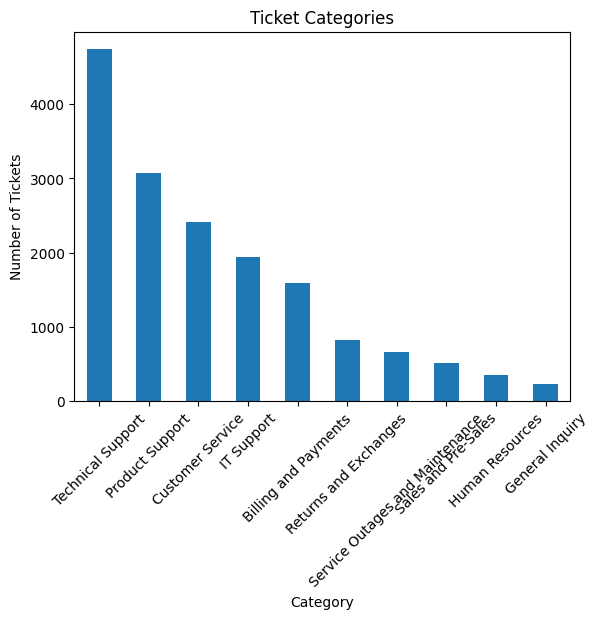

In [ ]:
print(processed.isnull().sum())
print("\nDataset shape:", processed.shape)
if "category" in processed.columns:
    print(processed["category"].value_counts())
import matplotlib.pyplot as plt

if "category" in processed.columns:
    processed["category"].value_counts().plot(kind="bar")

    plt.title("Ticket Categories")
    plt.xlabel("Category")
    plt.ylabel("Number of Tickets")
    plt.xticks(rotation=45)
    plt.show()

In [ ]:

print("Dataset shape:")
print(df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nSample records:")
display(df.head(10))

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape:
(16338, 16)

All columns:
['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']

Sample records:


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Thank you for your inquiry. Our product suppor...,Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN
5,Feature Query,"Dear Customer Support,\n\nI hope this message ...",Thank you for your inquiry. Please specify whi...,Request,Technical Support,high,en,51,Feature,Product,Documentation,Feedback,NaN,NaN,NaN,NaN
6,System Interruptions,"Dear Customer Support Team,\n\nI am submitting...",Thank you for bringing the system disruptions ...,Incident,Service Outages and Maintenance,high,en,51,Outage,Disruption,Performance,IT,Tech Support,NaN,NaN,NaN
7,Connectivity Problems with Printer on MacBook Pro,"Dear Support Team,\n\nI am reporting a recurri...",Thank you for reaching out regarding the conne...,Incident,Technical Support,medium,en,51,Network,Hardware,Performance,Bug,Compatibility,NaN,NaN,NaN
10,VPN Access Issue,"Customer Support,\n\nWe are encountering a dis...",Thank you for reporting this problem. Please p...,Incident,Product Support,medium,en,51,Network,Disruption,VPN,Tech Support,NaN,NaN,NaN,NaN
12,Immediate Help Needed: Technical Problem with ...,"Dear Customer Support Team,\n\nI am submitting...",Thanks for providing detailed information abou...,Problem,IT Support,medium,en,51,Bug,Crash,Network,Performance,Disruption,Outage,Tech Support,NaN
13,Inquiry for Detailed Information on Agency Off...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your interest in our agency's se...,Request,Product Support,high,en,51,Product,Service,Feedback,Sales,NaN,NaN,NaN,NaN



Missing values:
subject      2607
body            0
answer          3
type            0
queue           0
priority        0
language        0
version         0
tag_1           0
tag_2           6
tag_3          69
tag_4        1711
tag_5        7922
tag_6       12968
tag_7       15204
tag_8       16057
dtype: int64

Data types:
subject     object
body        object
answer      object
type        object
queue       object
priority    object
language    object
version      int64
tag_1       object
tag_2       object
tag_3       object
tag_4       object
tag_5       object
tag_6       object
tag_7       object
tag_8       object
dtype: object


In [ ]:

for col in ["queue", "type", "priority", "language"]:
    if col in df.columns:
        print("\n", col.upper())
        print(df[col].value_counts(dropna=False))



 QUEUE
queue
Technical Support                  4737
Product Support                    3073
Customer Service                   2410
IT Support                         1942
Billing and Payments               1595
Returns and Exchanges               820
Service Outages and Maintenance     664
Sales and Pre-Sales                 513
Human Resources                     348
General Inquiry                     236
Name: count, dtype: int64

 TYPE
type
Incident    6571
Request     4665
Problem     3397
Change      1705
Name: count, dtype: int64

 PRIORITY
priority
medium    6618
high      6346
low       3374
Name: count, dtype: int64

 LANGUAGE
language
en    16338
Name: count, dtype: int64


In [ ]:

import pandas as pd
import numpy as np
import re

# Create working copy
data = df.copy()

# Handle missing values
data["subject"] = data["subject"].fillna("")
data["body"] = data["body"].fillna("")
data["answer"] = data["answer"].fillna("")

# Combine subject and body
data["ticket_text"] = data["subject"] + " " + data["body"]

# Clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

data["ticket_text"] = data["ticket_text"].apply(clean_text)

# Remove records with missing labels or empty text
data = data.dropna(subset=["queue", "type", "priority"])
data = data[data["ticket_text"] != ""]

# Remove exact duplicate rows
data = data.drop_duplicates()

print("Preprocessing completed!")
print("Final shape:", data.shape)
print(data[["ticket_text", "queue", "type", "priority"]].head())


Preprocessing completed!
Final shape: (16338, 17)
                                         ticket_text                  queue  \
1  account disruption dear customer support team ...      Technical Support   
2  query about smart home system integration feat...  Returns and Exchanges   
3  inquiry regarding invoice details dear custome...   Billing and Payments   
4  question about marketing agency software compa...    Sales and Pre-Sales   
5  feature query dear customer support n ni hope ...      Technical Support   

       type priority  
1  Incident     high  
2   Request   medium  
3   Request      low  
4   Problem   medium  
5   Request     high  


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import accuracy_score, classification_report

X = data["ticket_text"]
y = data["queue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Improved TF-IDF
features = FeatureUnion([
    ("word", TfidfVectorizer(
        max_features=30000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=2
    )),
    ("char", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        max_features=20000
    ))
])

model = Pipeline([
    ("tfidf", features),
    ("classifier", LogisticRegression(
        C=4,
        max_iter=1500,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Improved Accuracy:", accuracy_score(y_test, y_pred) * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Improved Accuracy: 60.55691554467564

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.82      0.81      0.82       319
               Customer Service       0.53      0.59      0.56       482
                General Inquiry       0.58      0.62      0.60        47
                Human Resources       0.63      0.63      0.63        70
                     IT Support       0.51      0.58      0.54       388
                Product Support       0.55      0.54      0.55       615
          Returns and Exchanges       0.61      0.60      0.61       164
            Sales and Pre-Sales       0.56      0.64      0.60       103
Service Outages and Maintenance       0.67      0.77      0.72       133
              Technical Support       0.65      0.57      0.61       947

                       accuracy                           0.61      3268
                      macro avg       0.61      0.63      0.6

In [ ]:

import joblib

joblib.dump(model, "ticket_classifier.pkl")

print("Model saved successfully!")


Model saved successfully!


In [ ]:

ticket = "WIFI connection lost"

prediction = model.predict([ticket])

print("Predicted Ticket Category:", prediction[0])


Predicted Ticket Category: Technical Support


In [ ]:

data.to_csv("supportpilot_cleaned.csv", index=False)

from google.colab import files

files.download("supportpilot_cleaned.csv")
files.download("ticket_classifier.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.base import clone

X = data["ticket_text"]
y_priority = data["priority"]

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X, y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_priority
)

priority_model = clone(model)

priority_model.fit(X_train_p, y_train_p)

priority_pred = priority_model.predict(X_test_p)

print("Priority Accuracy:",
      accuracy_score(y_test_p, priority_pred) * 100)

print("\nClassification Report:")
print(classification_report(y_test_p, priority_pred))


Priority Accuracy: 67.38066095471235

Classification Report:
              precision    recall  f1-score   support

        high       0.71      0.71      0.71      1269
         low       0.61      0.63      0.62       675
      medium       0.68      0.66      0.67      1324

    accuracy                           0.67      3268
   macro avg       0.66      0.67      0.67      3268
weighted avg       0.67      0.67      0.67      3268



In [ ]:

def calculate_severity(ticket, priority):
    ticket = ticket.lower()

    if any(word in ticket for word in
           ["system down", "complete outage", "critical", "all users"]):
        return "Critical"

    elif priority == "high":
        return "High"

    elif priority == "medium":
        return "Medium"

    else:
        return "Low"


ticket = "VPN is not connecting and system is down"

predicted_priority = priority_model.predict([ticket])[0]

severity = calculate_severity(ticket, predicted_priority)

print("Priority:", predicted_priority)
print("Severity:", severity)


Priority: high
Severity: High


In [ ]:

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model, "models/ticket_classifier.pkl")

joblib.dump(priority_model, "models/priority_classifier.pkl")

data.to_csv("supportpilot_cleaned.csv", index=False)

print("Both models saved successfully!")


Both models saved successfully!


In [ ]:

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model, "models/ticket_classifier.pkl")
joblib.dump(priority_model, "models/priority_classifier.pkl")

data.to_csv("supportpilot_cleaned.csv", index=False)

print("All files saved successfully!")


All files saved successfully!


In [ ]:
from google.colab import files

files.download("models/ticket_classifier.pkl")
files.download("models/priority_classifier.pkl")
files.download("supportpilot_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

def supportpilot(ticket):
    category = model.predict([ticket])[0]
    priority = priority_model.predict([ticket])[0]
    severity = calculate_severity(ticket, priority)

    print("Ticket:", ticket)
    print("Category:", category)
    print("Priority:", priority)
    print("Severity:", severity)

supportpilot(
    "i have meeting in 1hr. my teams is not letting ,me log in. help me fast."
)


Ticket: i have meeting in 1hr. my teams is not letting ,me log in. help me fast.
Category: IT Support
Priority: high
Severity: High
